# Misión 2: Recomendaciones Inteligentes — Clustering de Productos
## Brazilian E-Commerce Public Dataset by Olist

La idea es agrupar productos parecidos para poder recomendar mejor y entender el catálogo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# para el clustering y reducción de dimensiones
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

print("Librerías importadas correctamente")

Librerías importadas correctamente


In [2]:
from pathlib import Path
DATA_PATH = Path('Datasets')

order_items = pd.read_csv(DATA_PATH / 'olist_order_items_dataset.csv')
products = pd.read_csv(DATA_PATH / 'olist_products_dataset.csv')
reviews = pd.read_csv(DATA_PATH / 'olist_order_reviews_dataset.csv')

print(f"order_items:  {order_items.shape}")
print(f"products:     {products.shape}")
print(f"reviews:      {reviews.shape}")

order_items:  (112650, 7)
products:     (32951, 9)
reviews:      (99224, 7)


## Preparar features

Para agrupar los productos necesitamos 4 características:
- **price**: precio promedio del producto
- **freight_value**: flete promedio
- **review_score**: calificación promedio
- **total_sales**: cantidad de veces que se vendió

In [3]:
# precio y flete promedio por producto
product_stats = order_items.groupby('product_id').agg(
    price=('price', 'mean'),
    freight_value=('freight_value', 'mean'),
    total_sales=('order_id', 'count')
).reset_index()

#hay que pasar por order_items para llegar al producto, como los datasets son de una base de datos, y el review se hace sobre un pedido, no sobre el producto
#por lo que hay que pasar por order_items que es la tabla que conecta pedidos con productos
review_scores = reviews.groupby('order_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

order_items_reviews = order_items[['order_id', 'product_id']].merge(review_scores, on='order_id')
product_reviews = order_items_reviews.groupby('product_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

# Unir todo
df = product_stats.merge(product_reviews, on='product_id', how='left')
#sin ninguna review no tiene score, y no tiene sentido inventar un valor para meterlo al clustering. Es mejor descartarlo
df = df.dropna()

print(f"Productos para modelar: {df.shape[0]:,}")
print(df[['price', 'freight_value', 'review_score', 'total_sales']].describe().round(2))

Productos para modelar: 32,789
          price  freight_value  review_score  total_sales
count  32789.00       32789.00      32789.00     32789.00
mean     145.16          21.20          4.05         3.43
std      244.46          18.07          1.21        10.64
min        0.85           0.01          1.00         1.00
25%       39.90          13.60          3.60         1.00
50%       79.00          16.70          4.50         1.00
75%      154.94          21.83          5.00         3.00
max     6735.00         409.68          5.00       527.00


In [4]:
features = ['price', 'freight_value', 'review_score', 'total_sales']

# se busca cómo manejar valores extremos y encontrar que log1p funciona bien
# price y total_sales tienen valores extremos, aplicar log1p antes de escalar
df_model = df.copy()
df_model['total_sales'] = np.log1p(df_model['total_sales'])
df_model['price'] = np.log1p(df_model['price'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model[features])

print(f"Listo. Shape: {X_scaled.shape}")

Listo. Shape: (32789, 4)


## Elegir el número de clusters (K)

Probamos K entre 2 y 8 y usamos dos métodos:
- **Elbow method:** graficamos la inercia por K, buscamos donde la curva se aplana
- **Silhouette Score:** valores más cercanos a 1 indican clusters más separados

In [5]:
inercias = []
silhouettes = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inercias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, kmeans.labels_))
    print(f"K={k}: Inercia={kmeans.inertia_:.0f} | Silhouette={silhouette_score(X_scaled, kmeans.labels_):.4f}")

K=2: Inercia=106074 | Silhouette=0.3130
K=3: Inercia=84236 | Silhouette=0.3175
K=4: Inercia=63204 | Silhouette=0.3601
K=5: Inercia=50260 | Silhouette=0.3089
K=6: Inercia=45436 | Silhouette=0.2963
K=7: Inercia=41360 | Silhouette=0.2942
K=8: Inercia=38019 | Silhouette=0.2579


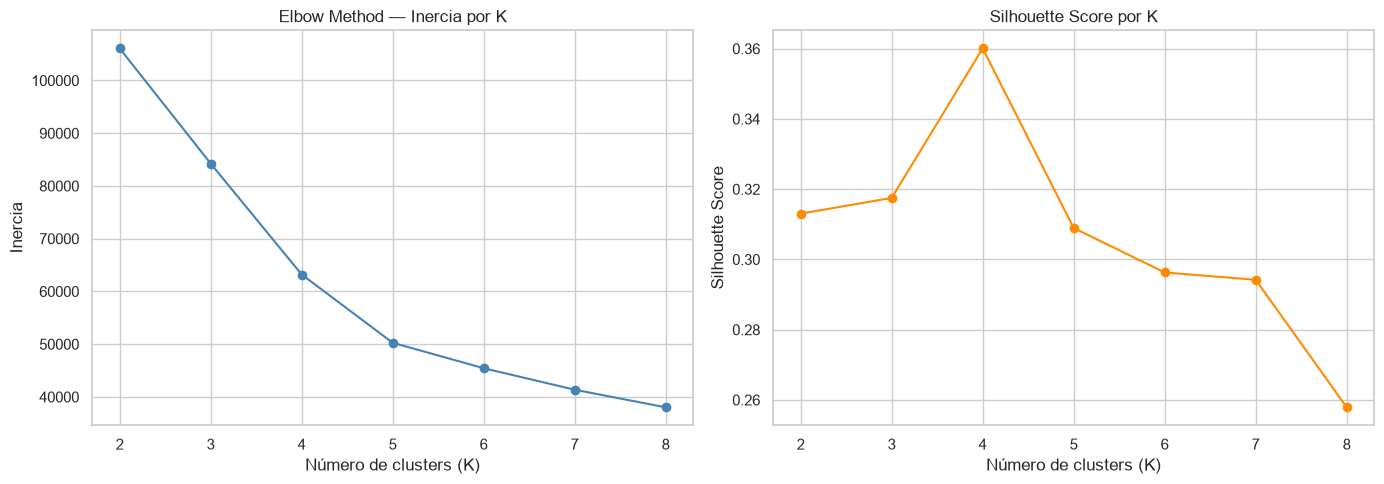

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow
ax1.plot(k_range, inercias, marker='o', color='steelblue')
ax1.set_title('Elbow Method — Inercia por K')
ax1.set_xlabel('Número de clusters (K)')
ax1.set_ylabel('Inercia')

# Silhouette
ax2.plot(k_range, silhouettes, marker='o', color='darkorange')
ax2.set_title('Silhouette Score por K')
ax2.set_xlabel('Número de clusters (K)')
ax2.set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

## Entrenar K-Means con K=5

Mirando los gráficos, K=5 parece un buen balance — el codo se aplana ahí. El silhouette baja un poco respecto a K=4 pero con K=5 se pueden interpretar mejor los grupos.

In [7]:
K_OPTIMO = 5

# entrenar con K=5 y asignar cluster a cada producto
kmeans = KMeans(n_clusters=K_OPTIMO, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

print(f"K-Means entrenado con K={K_OPTIMO}")
print("\nDistribución de productos por cluster:")
for cluster, count in df['cluster'].value_counts().sort_index().items():
    pct = count / len(df) * 100
    print(f"  Cluster {cluster}: {count:,} productos ({pct:.1f}%)")

K-Means entrenado con K=5

Distribución de productos por cluster:
  Cluster 0: 5,452 productos (16.6%)
  Cluster 1: 10,006 productos (30.5%)
  Cluster 2: 1,050 productos (3.2%)
  Cluster 3: 4,598 productos (14.0%)
  Cluster 4: 11,683 productos (35.6%)


## Perfil de cada cluster

Veamos qué características tiene cada grupo para darle un nombre de negocio.

In [8]:
perfil = df.groupby('cluster')[features].mean().round(2)
perfil['n_productos'] = df.groupby('cluster').size()
print(perfil)

          price  freight_value  review_score  total_sales  n_productos
cluster                                                               
0        125.26          19.24          1.84         1.56         5452
1        246.89          23.19          4.61         1.62        10006
2        647.83          96.17          3.92         1.77         1050
3         92.56          18.21          4.04        14.59         4598
4         42.84          14.84          4.61         1.61        11683


In [9]:
nombres = {
    0: 'Económico',
    1: 'Premium',
    2: 'Alta Rotación / Best Sellers',
    3: 'Baja Calificación / Riesgo',
    4: 'Muy Caros'
}

df['cluster_nombre'] = df['cluster'].map(nombres)

print("Distribución final:")
for cluster, nombre in nombres.items():
    count = (df['cluster'] == cluster).sum()
    pct = count / len(df) * 100
    print(f"  {nombre}: {count:,} productos ({pct:.1f}%)")

Distribución final:
  Económico: 5,452 productos (16.6%)
  Premium: 10,006 productos (30.5%)
  Alta Rotación / Best Sellers: 1,050 productos (3.2%)
  Baja Calificación / Riesgo: 4,598 productos (14.0%)
  Muy Caros: 11,683 productos (35.6%)


## Visualización con PCA

Como tenemos 4 features no podemos graficar directamente. PCA las reduce a 2 (o 3) dimensiones para poder ver los clusters. Es solo para visualizar, no cambia el modelo.

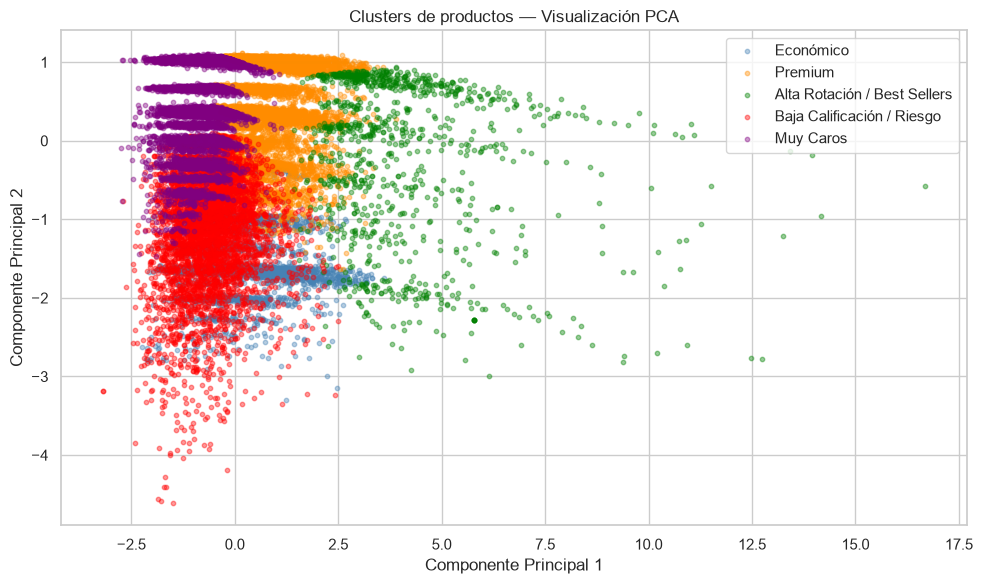


Varianza explicada por los 2 componentes: 61.6%


In [10]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
colores = ['steelblue', 'darkorange', 'green', 'red', 'purple']

for cluster, nombre in nombres.items():
    mask = df['cluster'] == cluster
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                label=nombre, alpha=0.4, s=10, color=colores[cluster])

plt.title('Clusters de productos — Visualización PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(f"\nVarianza explicada por los 2 componentes: {pca.explained_variance_ratio_.sum()*100:.1f}%")

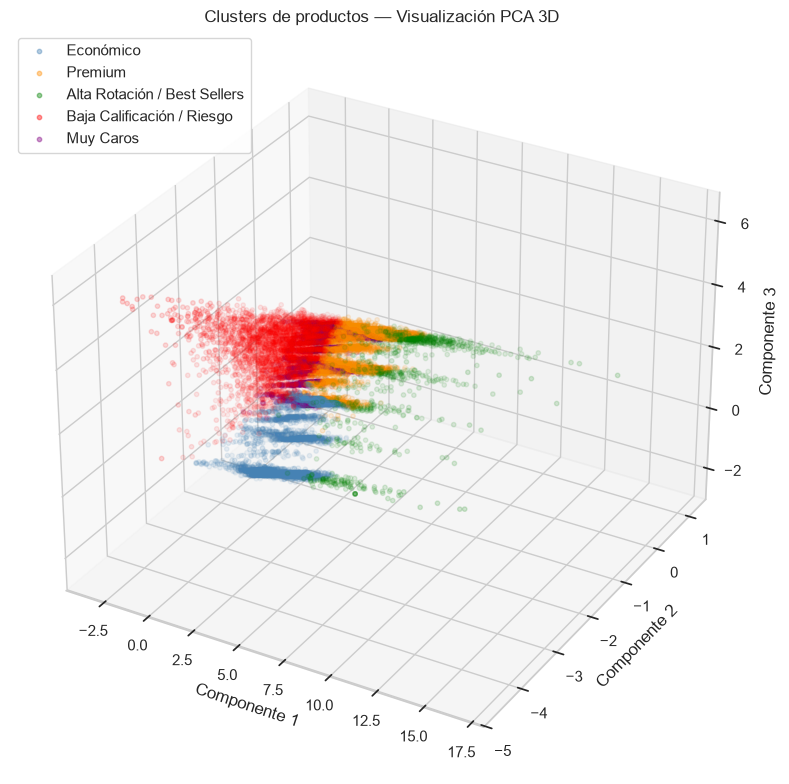


Varianza explicada por los 3 componentes: 85.9%


In [11]:
from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

colores = ['steelblue', 'darkorange', 'green', 'red', 'purple']

for cluster, nombre in nombres.items():
    mask = df['cluster'] == cluster
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], X_pca[mask, 2],
               label=nombre, alpha=0.4, s=10, color=colores[cluster])

ax.set_title('Clusters de productos — Visualización PCA 3D')
ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.set_zlabel('Componente 3')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f"\nVarianza explicada por los 3 componentes: {pca.explained_variance_ratio_.sum()*100:.1f}%")

## Conclusiones

Después de analizar el perfil de cada cluster:

- **Cluster 0 — Económico** (35.8%): precio bajo ~43, buen score 4.6
- **Cluster 1 — Premium** (30.3%): precio alto ~248, también buen score
- **Cluster 2 — Alta Rotación** (14.0%): precio medio pero se vende mucho, promedio 14.5 ventas
- **Cluster 3 — Baja Calificación** (16.6%): score 1.84, claramente productos con problemas
- **Cluster 4 — Muy Caros** (3.2%): precio ~648 y flete ~96, nicho muy específico

Lo más útil sería enfocarse en el Cluster 3 para mejorar calidad, y asegurar stock del Cluster 2.

## Nota Overfitting en Clustering

K-Means no usa Pipeline de la misma manera que los modelos supervisados — no hay target que predecir ni train/test split clásico.

El equivalente al "overfitting" en clustering se analiza con la curva de inercia: si eligiéramos K muy alto (como K=8), el modelo se ajustaría demasiado a los datos y perdería generalidad. Por eso el método del codo ayuda a encontrar un K razonable.



Limitación del enfoque: estos clusters agrupan productos por segmento de mercado (precio, flete, calificación y popularidad), no por afinidad funcional entre productos. Dos productos del mismo cluster comparten un perfil comercial similar, pero no necesariamente son productos relacionados por uso o categoría — un auricular caro y un reloj caro pueden estar en el mismo cluster Premium. Para recomendaciones del tipo “compraste una cafetera, te recomiendo café”, se necesitaría una capa adicional como análisis de co-ocurrencia de productos dentro del mismo pedido, que no fue el alcance de esta misión. Los clusters sí son útiles para decisiones de negocio por segmento: mejorar calidad en Cluster 3, asegurar stock en Cluster 2, o estrategia de precios diferenciada por segmento.

## Recomendador por Cluster + Categoría

El clustering agrupa productos por perfil comercial. Para que las recomendaciones tengan sentido funcional, filtramos además por categoría del producto. Así un producto Premium solo compite con otros productos Premium de la misma categoría.

In [12]:
# cargamos products para obtener la categoría de cada producto
# y el CSV de traducción para trabajar con nombres en inglés
products = pd.read_csv(DATA_PATH / 'olist_products_dataset.csv')
translations = pd.read_csv(DATA_PATH / 'product_category_name_translation.csv')

# unir traducción al inglés
products = products.merge(translations, on='product_category_name', how='left')

print(f"Productos cargados: {len(products):,}")
print(f"Con categoría en inglés: {products['product_category_name_english'].notna().sum():,}")
print(f"Categorías únicas: {products['product_category_name_english'].nunique()}")

Productos cargados: 32,951
Con categoría en inglés: 32,328
Categorías únicas: 71


In [13]:
# unimos la categoría en inglés a cada producto que ya tiene su cluster asignado
df = df.merge(
    products[['product_id', 'product_category_name_english']],
    on='product_id',
    how='left'
)

print(f"Productos con categoría asignada: {df['product_category_name_english'].notna().sum():,}")
print(f"Productos sin categoría: {df['product_category_name_english'].isna().sum():,}")

Productos con categoría asignada: 32,171
Productos sin categoría: 618


In [14]:
from sklearn.metrics.pairwise import euclidean_distances

def recomendar_productos(product_id, df, X_scaled, n=5):
    """
    Recomienda productos del mismo cluster y categoría,
    ordenados por distancia euclidiana en el espacio de features escaladas.

    Parámetros:
    - product_id: ID del producto de referencia
    - df: DataFrame con columnas cluster_nombre, product_category_name_english, price, review_score, total_sales
    - X_scaled: array numpy con las features escaladas (mismo orden que df)
    - n: cantidad de recomendaciones a devolver
    """
    # verificar que el producto exista
    if product_id not in df['product_id'].values:
        print(f"Producto {product_id} no encontrado en el dataset.")
        return None

    # obtener el índice posicional en el array X_scaled
    idx = df[df['product_id'] == product_id].index[0]
    pos = df.index.get_loc(idx)

    # datos del producto de referencia
    cluster_objetivo   = df.loc[idx, 'cluster_nombre']
    categoria_objetivo = df.loc[idx, 'product_category_name_english']

    print(f"Producto buscado : {product_id}")
    print(f"Cluster          : {cluster_objetivo}")
    print(f"Categoría        : {categoria_objetivo}")
    print(f"Precio           : R$ {df.loc[idx, 'price']:.2f}")
    print(f"Review score     : {df.loc[idx, 'review_score']:.2f}")
    print(f"Ventas totales   : {df.loc[idx, 'total_sales']:.0f}")
    print("-" * 55)

    # filtrar candidatos: mismo cluster Y misma categoría, excluyendo el producto buscado
    mascara = (
        (df['cluster_nombre'] == cluster_objetivo) &
        (df['product_category_name_english'] == categoria_objetivo) &
        (df['product_id'] != product_id)
    )
    candidatos = df[mascara].copy()

    if len(candidatos) == 0:
        print("No hay otros productos en el mismo cluster y categoría.")
        return None

    # calcular distancia euclidiana entre el producto buscado y cada candidato
    # distancia menor = más parecido en el espacio de features
    vec_objetivo = X_scaled[pos].reshape(1, -1)
    posiciones_candidatos = [df.index.get_loc(i) for i in candidatos.index]
    dist = euclidean_distances(vec_objetivo, X_scaled[posiciones_candidatos])[0]
    candidatos['distancia'] = dist

    # devolver los n más cercanos
    recomendados = candidatos.nsmallest(n, 'distancia')[
        ['product_id', 'cluster_nombre', 'product_category_name_english',
         'price', 'review_score', 'total_sales', 'distancia']
    ].reset_index(drop=True)

    print(f"Top {n} recomendaciones (mismo cluster + categoría, ordenadas por similitud):")
    print(recomendados.to_string(index=False))
    return recomendados


# --- Ejemplo de uso ---
# tomamos el primer producto del cluster Premium para probar
producto_ejemplo = df[df['cluster_nombre'] == 'Premium']['product_id'].iloc[0]
recomendados = recomendar_productos(producto_ejemplo, df, X_scaled)

Producto buscado : 00066f42aeeb9f3007548bb9d3f33c38
Cluster          : Premium
Categoría        : perfumery
Precio           : R$ 101.65
Review score     : 5.00
Ventas totales   : 1
-------------------------------------------------------
Top 5 recomendaciones (mismo cluster + categoría, ordenadas por similitud):
                      product_id cluster_nombre product_category_name_english  price  review_score  total_sales  distancia
ac06fe86362d2401d00a5a03a1e693ac        Premium                     perfumery   98.0           5.0            1   0.037818
5daa4a09c9afb3b30d6df995fab5c2dc        Premium                     perfumery  100.0           5.0            1   0.050273
624a71194ff2a5badf71b7870f88f24f        Premium                     perfumery  108.0           5.0            1   0.061653
dc582e9ac5036846acfeeb3093b17aa7        Premium                     perfumery  104.9           5.0            1   0.065926
06a63a471d8a08878526b37a1baa66a5        Premium                     per

## Conclusión del recomendador

La recomendación usa dos capas:

1. **Cluster**: filtra productos con perfil comercial similar (precio, flete, calificación, popularidad).
2. **Categoría**: dentro del cluster, solo productos de la misma categoría funcional.
3. **Distancia euclidiana**: ordena los candidatos por similitud real en el espacio de features — el más cercano es el más parecido numéricamente.

Esto resuelve la limitación del clustering puro: un auricular Premium solo compite con otros auriculares Premium, no con cualquier producto caro.

**Limitación que persiste**: la distancia euclidiana mide similitud de perfil comercial, no de uso. Para recomendaciones del tipo "compraste esto, llevate esto" haría falta análisis de co-ocurrencia de productos dentro del mismo pedido.